# E2 · Notebook 1 — Entorno, datos Sen1Floods11, línea base y teardown

**NO EJECUTADO.** Solo E2. Parte 1 de 2: deja en **tu Drive** (`MyDrive/auto-prompt-sam2`) los datos y la evidencia de la línea base (SAM 2.1 tiny congelado) y del teardown. Reutiliza el código del repositorio (`prepare_stage2.py`, `run_stage3.py`, `run_stage4.py`).

* Runtime: **T4 GPU**. Todo el código se clona desde GitHub (rama `_E.V_`) y su commit queda fijado en tu Drive.
* Los datos, pesos, cachés y checkpoints se guardan solo en tu Drive, nunca en GitHub.
* Referencia asistida por etiquetas (no desplegable). No se usa el flujo automático DINOv3→SAM.
* La evidencia ejecutada de tu compañero en `docs/project/evidence/` es antecedente; **no acredita tu ejecución**.
* Licencia de Sen1Floods11: respuesta del publicador pendiente.

## 1. Entorno
Clona el código, fija el commit, crea el entorno aislado y lee `HF_TOKEN` de los secretos de Colab (sin mostrarlo).

In [1]:
from pathlib import Path
import json, os, subprocess, sys
from google.colab import drive

drive.mount('/content/drive')
GITHUB_URL = 'https://github.com/roberto-chavez/auto-prompt-sam2.git'
BRANCH = '_E.V_'
PINNED_COMMIT = ''    # '' = usa el commit ya fijado en tu Drive; en la 1.ª ejecución fija la punta actual de la rama
UPDATE_CODE = False   # True SOLO para adoptar código nuevo de la rama (entonces rehaz E2 desde 'prepare')
PERSIST_ROOT = '/content/drive/MyDrive/auto-prompt-sam2'   # datos, pesos, cachés y checkpoints: SOLO aquí
REPO = Path('/content/auto-prompt-sam2')
PYTHON = Path('/content/auto-prompt-venv/bin/python')
Path(PERSIST_ROOT).mkdir(parents=True, exist_ok=True)

def sh(args, cwd=None):
    r = subprocess.run(args, cwd=cwd, text=True, capture_output=True)
    if r.returncode:
        raise RuntimeError(f'{args[:3]} falló:\n{r.stdout}\n{r.stderr}')
    return r.stdout.strip()

# --- Código desde GitHub, en una revisión fijada y reproducible --------------------------------------
PIN_FILE = Path(PERSIST_ROOT) / 'e2/code_commit.txt'
existed = REPO.exists()
if not existed:
    sh(['git', 'clone', '--branch', BRANCH, GITHUB_URL, str(REPO)])
elif UPDATE_CODE:
    sh(['git', 'fetch', 'origin', BRANCH], cwd=REPO)
want = PINNED_COMMIT.strip() or ('' if UPDATE_CODE or not PIN_FILE.exists() else PIN_FILE.read_text().strip())
if UPDATE_CODE and existed and not PINNED_COMMIT.strip():
    want = sh(['git', 'rev-parse', 'FETCH_HEAD'], cwd=REPO)
if want:
    sh(['git', 'checkout', '--detach', want], cwd=REPO)
COMMIT = sh(['git', 'rev-parse', 'HEAD'], cwd=REPO)
assert not sh(['git', 'status', '--porcelain'], cwd=REPO), 'El código clonado tiene cambios locales'
if PINNED_COMMIT.strip() or UPDATE_CODE or not PIN_FILE.exists():
    PIN_FILE.parent.mkdir(parents=True, exist_ok=True)
    PIN_FILE.write_text(COMMIT)
print('Código:', GITHUB_URL, '| rama', BRANCH, '| commit', COMMIT)
print('Commit fijado en Drive:', PIN_FILE.read_text().strip())

# --- Entorno ----------------------------------------------------------------------------------------
child_env = dict(os.environ, PYTHONPATH=str(REPO / 'src'),
    AUTO_PROMPT_PERSIST_ROOT=PERSIST_ROOT, PYTHONHASHSEED='42',
    CUBLAS_WORKSPACE_CONFIG=':4096:8', HF_HUB_DISABLE_TELEMETRY='1',
    AUTO_PROMPT_EXECUTION_CONTEXT='google_colab_user_notebook')
try:   # HF_TOKEN se lee de los secretos de Colab (activa "Acceso desde el notebook"); nunca se imprime ni se guarda
    from google.colab import userdata
    child_env['HF_TOKEN'] = userdata.get('HF_TOKEN')
    print('HF_TOKEN leído de los secretos de Colab (valor no mostrado).')
except Exception as error:
    print('HF_TOKEN no disponible (' + type(error).__name__ + '): SAM es público; solo DINOv3 lo necesita.')
LOG_DIR = Path(PERSIST_ROOT) / 'e2/notebook_logs'
LOG_DIR.mkdir(parents=True, exist_ok=True)

def command(args, log_name):
    """Ejecuta un proceso mostrando su salida en vivo y guardándola en Drive."""
    with (LOG_DIR / log_name).open('w', encoding='utf-8') as log:
        process = subprocess.Popen(args, cwd=REPO, env=child_env, text=True,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, bufsize=1)
        for line in process.stdout:
            print(line, end='')
            log.write(line)
            log.flush()
        result = process.wait()
    if result:
        raise RuntimeError(f'Proceso terminado con código {result}; revisa la salida y el log {log_name}')

if not PYTHON.is_file():
    command([sys.executable, str(REPO / 'scripts/bootstrap_colab.py'), '--venv', str(PYTHON.parent.parent)], 'bootstrap.log')
command([str(PYTHON), '-m', 'pip', 'install', '--no-deps', '-r', str(REPO / 'requirements-stage2.txt')], 'stage2_pins.log')
command([str(PYTHON), '-m', 'pip', 'check'], 'pip_check.log')
print('Entorno listo.')

Mounted at /content/drive
Código: https://github.com/roberto-chavez/auto-prompt-sam2.git | rama _E.V_ | commit f399047464b89a3ed18972f8dc7f1b1364d83a44
Commit fijado en Drive: f399047464b89a3ed18972f8dc7f1b1364d83a44
HF_TOKEN leído de los secretos de Colab (valor no mostrado).
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 104.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 96.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 12.4 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 143.1 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 25.7 MB/s  0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 42.4 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2

In [2]:
# Comprueba que Colab te dio una GPU (Entorno de ejecución > Cambiar tipo > T4 GPU).
command(['nvidia-smi'], 'nvidia_smi.log')
command([str(PYTHON), '-c', 'import torch; assert torch.cuda.is_available(), "NO HAY GPU: cambia el tipo de entorno a GPU"; print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)'], 'gpu_check.log')

Fri Oct 30 00:50:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Datos (etapa 2): descarga y preparación de Sen1Floods11
Descarga los 446 pares a tu Drive, audita, crea splits y fija estadísticas con **solo train**. No abre test ni Bolivia para ajustar nada.

In [3]:
# Descarga Sen1Floods11 v1.1 (446 pares S2Hand/LabelHand) a TU Drive, audita, crea los splits y fija el preprocesamiento.
# Es la parte más lenta. Es reanudable: si Colab se corta, vuelve a ejecutar las celdas de entorno y esta.
command([str(PYTHON), str(REPO / 'scripts/prepare_stage2.py'), '--root', PERSIST_ROOT,
         '--evidence', str(Path(PERSIST_ROOT) / 'stage2/evidence')], 'stage2_prepare.log')

Auditing 446 image/label pairs (structure only on reserved sets)
Preparing official {'train': 252, 'val': 89, 'test': 90, 'bolivia': 15}
Preparing leave_paraguay_out {'train': 213, 'val': 75, 'test': 76, 'paraguay_reserved': 67, 'bolivia': 15}
{
  "status": "data_preprocessing_checks_passed",
  "regimes": {
    "official": {
      "counts": {
        "train": 252,
        "val": 89,
        "test": 90,
        "bolivia": 15
      },
      "manifest_sha256": "2352d7785183fe5713cf9354ffb430b236c1edc888bb7275d2f93fb328f4b43a",
      "manifest_generation": "20261030T005447707965Z_92758313e585",
      "preprocessing_sha256": "a48c5416612393d1d1d96c4cfa0aac29588e8c96581538d6e2c89bbeb9c271fd",
      "parameter_generation": "20261030T005458988292Z_ef7168e03839",
      "parameters_reused": false,
      "upper_dn": 4796.0,
      "upper_reflectance": 0.4796,
      "fit_train_chips": 252,
      "validity_masks": 341,
      "reload": {
        "chip": "Ghana_103272",
        "tensor_sha256": {
    

In [4]:
# Segunda pasada sin red: relee todo desde tu Drive y comprueba que coincide.
command([str(PYTHON), str(REPO / 'scripts/prepare_stage2.py'), '--root', PERSIST_ROOT, '--offline',
         '--evidence', str(Path(PERSIST_ROOT) / 'stage2/evidence')], 'stage2_offline.log')
report = json.loads((Path(PERSIST_ROOT) / 'stage2/evidence/validation.json').read_text())
print(json.dumps({k: {'counts': v['counts'], 'parameters_reused': v['parameters_reused'], 'reload': v['reload']}
                  for k, v in report['regimes'].items()}, indent=2))
assert report['models_executed'] is False and report['reserved_pixel_caches'] == []

Auditing 446 image/label pairs (structure only on reserved sets)
Preparing official {'train': 252, 'val': 89, 'test': 90, 'bolivia': 15}
Preparing leave_paraguay_out {'train': 213, 'val': 75, 'test': 76, 'paraguay_reserved': 67, 'bolivia': 15}
{
  "status": "data_preprocessing_checks_passed",
  "regimes": {
    "official": {
      "counts": {
        "train": 252,
        "val": 89,
        "test": 90,
        "bolivia": 15
      },
      "manifest_sha256": "2352d7785183fe5713cf9354ffb430b236c1edc888bb7275d2f93fb328f4b43a",
      "manifest_generation": "20261030T005758625273Z_6ae071da9576",
      "preprocessing_sha256": "a48c5416612393d1d1d96c4cfa0aac29588e8c96581538d6e2c89bbeb9c271fd",
      "parameter_generation": "20261030T005758723167Z_d392212a6ef0",
      "parameters_reused": true,
      "upper_dn": 4796.0,
      "upper_reflectance": 0.4796,
      "fit_train_chips": 252,
      "validity_masks": 341,
      "reload": {
        "chip": "Ghana_103272",
        "tensor_sha256": {
     

## 3. Línea base (etapa 3)
SAM 2.1 tiny congelado sobre train/val con puntos simulados (1 positivo + 1 negativo por componente de agua). Máscara elegida por IoU **predicho**. Las métricas de esta celda son tuyas y **solo se interpretan tras revisar tus salidas**.

In [5]:
# Reutiliza scripts/run_stage3.py: SAM 2.1 tiny congelado, puntos simulados desde etiquetas (referencia asistida), evaluador común.
MODE3 = 'prepare'
command([str(PYTHON), str(REPO / 'scripts/run_stage3.py'), MODE3, '--root', PERSIST_ROOT], 'stage3_' + MODE3 + '.log')

Stage 3 prepare 20261030T005913Z_9411883ce3_bf1a453a
 test_current_config_is_valid_and_matches_stage3 (test_e2.ConfigContract.test_current_config_is_valid_and_matches_stage3) ... ok
test_paired_deltas (test_e2.ConfigContract.test_paired_deltas) ... ok
test_rejects_different_prompts_or_regime (test_e2.ConfigContract.test_rejects_different_prompts_or_regime) ... ok
test_audit_detects_gradient_outside_decoder_and_configure_refreezes (test_e2.Freezing.test_audit_detects_gradient_outside_decoder_and_configure_refreezes) ... ok
test_configure_rejects_nothing_to_train (test_e2.Freezing.test_configure_rejects_nothing_to_train) ... ok
test_only_decoder_trainable_and_frozen_hash_stable (test_e2.Freezing.test_only_decoder_trainable_and_frozen_hash_stable) ... ok
test_all_invalid_chip_has_no_loss (test_e2.Losses.test_all_invalid_chip_has_no_loss) ... ok
test_hand_calculated_bce_dice (test_e2.Losses.test_hand_calculated_bce_dice) ... ok
test_invalid_pixels_never_change_loss_or_gradient (test_e2.Los

In [6]:
RUNS3 = sorted(p for p in (Path(PERSIST_ROOT) / 'stage3/evidence').iterdir() if p.is_dir() and (p / 'validation.json').is_file())
assert RUNS3, 'No hay run completo de la etapa 3; revisa e2/notebook_logs/stage3_prepare.log'
R3 = json.loads((RUNS3[-1] / 'validation.json').read_text())
print('run_id:', R3['run_id'], '| estado:', R3['status'])
for regime, value in R3['regimes'].items():
    v = value['summary']['val']['pooled']['values']
    print(regime, '-> val agrupado: IoU agua', v['water_iou'], '| precisión', v['precision'], '| recall', v['recall'], '| Dice', v['dice'])

run_id: 20261030T005913Z_9411883ce3_bf1a453a | estado: development_checks_passed_pending_review
leave_paraguay_out -> val agrupado: IoU agua 0.16843410065333406 | precisión 0.16933622349844335 | recall 0.9693406998711249 | Dice 0.28830740314606285
official -> val agrupado: IoU agua 0.15804373108830588 | precisión 0.1610729199885264 | recall 0.8936595154193882 | Dice 0.2729495041431287


## 4. Teardown del modelo base (etapa 4, solo SAM)
Parámetros y FLOPs por bloque, features intermedias, mapa de campo receptivo, latencia y memoria máxima en la GPU que te asignó Colab.

In [7]:
# Teardown del modelo base (SAM 2.1 tiny): parámetros/FLOPs por bloque, features intermedias, ERF, latencia y memoria.
# Solo SAM: DINOv3 es opcional y no bloquea E2.
command([str(PYTHON), str(REPO / 'scripts/run_stage4.py'), 'prepare', '--models', 'sam', '--root', PERSIST_ROOT], 'stage4_sam_prepare.log')

 test_current_config_is_valid_and_matches_stage3 (test_e2.ConfigContract.test_current_config_is_valid_and_matches_stage3) ... ok
test_paired_deltas (test_e2.ConfigContract.test_paired_deltas) ... ok
test_rejects_different_prompts_or_regime (test_e2.ConfigContract.test_rejects_different_prompts_or_regime) ... ok
test_audit_detects_gradient_outside_decoder_and_configure_refreezes (test_e2.Freezing.test_audit_detects_gradient_outside_decoder_and_configure_refreezes) ... ok
test_configure_rejects_nothing_to_train (test_e2.Freezing.test_configure_rejects_nothing_to_train) ... ok
test_only_decoder_trainable_and_frozen_hash_stable (test_e2.Freezing.test_only_decoder_trainable_and_frozen_hash_stable) ... ok
test_all_invalid_chip_has_no_loss (test_e2.Losses.test_all_invalid_chip_has_no_loss) ... ok
test_hand_calculated_bce_dice (test_e2.Losses.test_hand_calculated_bce_dice) ... ok
test_invalid_pixels_never_change_loss_or_gradient (test_e2.Losses.test_invalid_pixels_never_change_loss_or_gradient

run_id: 20261030T011345Z_8315d17272_bc78f77e | modelos: ['sam']
[
 {
  "arithmetic_share_by_block": {
   "image_encoder": 0.9822044240659831,
   "residual": 0.0054473907897350056,
   "sam_mask_decoder": 0.012348179956000816,
   "sam_prompt_encoder": 5.188281113232046e-09
  },
  "counted_forward_flops_partial": 296051807232,
  "erf_mass_outside_central_half_by_train_chip": {
   "Ghana_103272": 0.38162535429000854,
   "Ghana_1089161": 0.36526668071746826
  },
  "median_ms": 152.60828249984115,
  "model": "sam",
  "peak_allocated_bytes": 684419584,
  "regime": "official"
 },
 {
  "arithmetic_share_by_block": {
   "image_encoder": 0.9822044240659831,
   "residual": 0.0054473907897350056,
   "sam_mask_decoder": 0.012348179956000816,
   "sam_prompt_encoder": 5.188281113232046e-09
  },
  "counted_forward_flops_partial": 296051807232,
  "erf_mass_outside_central_half_by_train_chip": {
   "Ghana_103272": 0.3818742632865906,
   "Ghana_1089161": 0.3653066158294678
  },
  "median_ms": 154.93332700

block,executed_calls,counted_flops
image_encoder,1,290783394816
sam_prompt_encoder,1,1536
sam_mask_decoder,1,3655700992
memory_attention,0,
memory_encoder,0,
obj_ptr_proj,0,
obj_ptr_tpos_proj,0,
residual,,1612709888


sam_leave_paraguay_out_0_timings.csv


block,median_ms,min_ms,max_ms,warmup,repetitions,baseline_allocated_bytes,baseline_reserved_bytes,peak_allocated_bytes,peak_reserved_bytes,incremental_peak_allocated_bytes,scope,batch_size,precision,autocast,synchronization,cache,calls_in_full_path,status
full_static_path,154.933327000208,135.89020400013396,159.25436299994544,5,20,382429696,2191523840,684419584,2191523840,301989888,preloaded_inputs_and_weights_no_hooks_no_io_no_backward,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,,
image_encoder,129.86286449995532,125.6549179997819,132.17078099978607,5,20,395012608,2191523840,697002496,2191523840,301989888,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1,
sam_prompt_encoder,1.4192554999681306,1.064094999946974,3.3751400001165166,5,20,382430720,2191523840,382443008,2191523840,12288,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1,
sam_mask_decoder,31.265984500123523,28.961903999970673,46.9002019999607,5,20,407598592,2191523840,437043712,2191523840,29445120,isolated_module_replay_preloaded_first_call_inputs_no_transfers_no_hooks_no_io,1,float32,False,cuda_synchronize_before_and_after_each_host_wall_clock_sample,warm_allocator_and_model_caches_no_empty_cache_between_repetitions,1,
memory_attention,,,,,,,,,,,,,,,,,,not_executed_static_image_path
memory_encoder,,,,,,,,,,,,,,,,,,not_executed_static_image_path
obj_ptr_proj,,,,,,,,,,,,,,,,,,not_executed_static_image_path
obj_ptr_tpos_proj,,,,,,,,,,,,,,,,,,not_executed_static_image_path


sam_leave_paraguay_out_0_figure.png


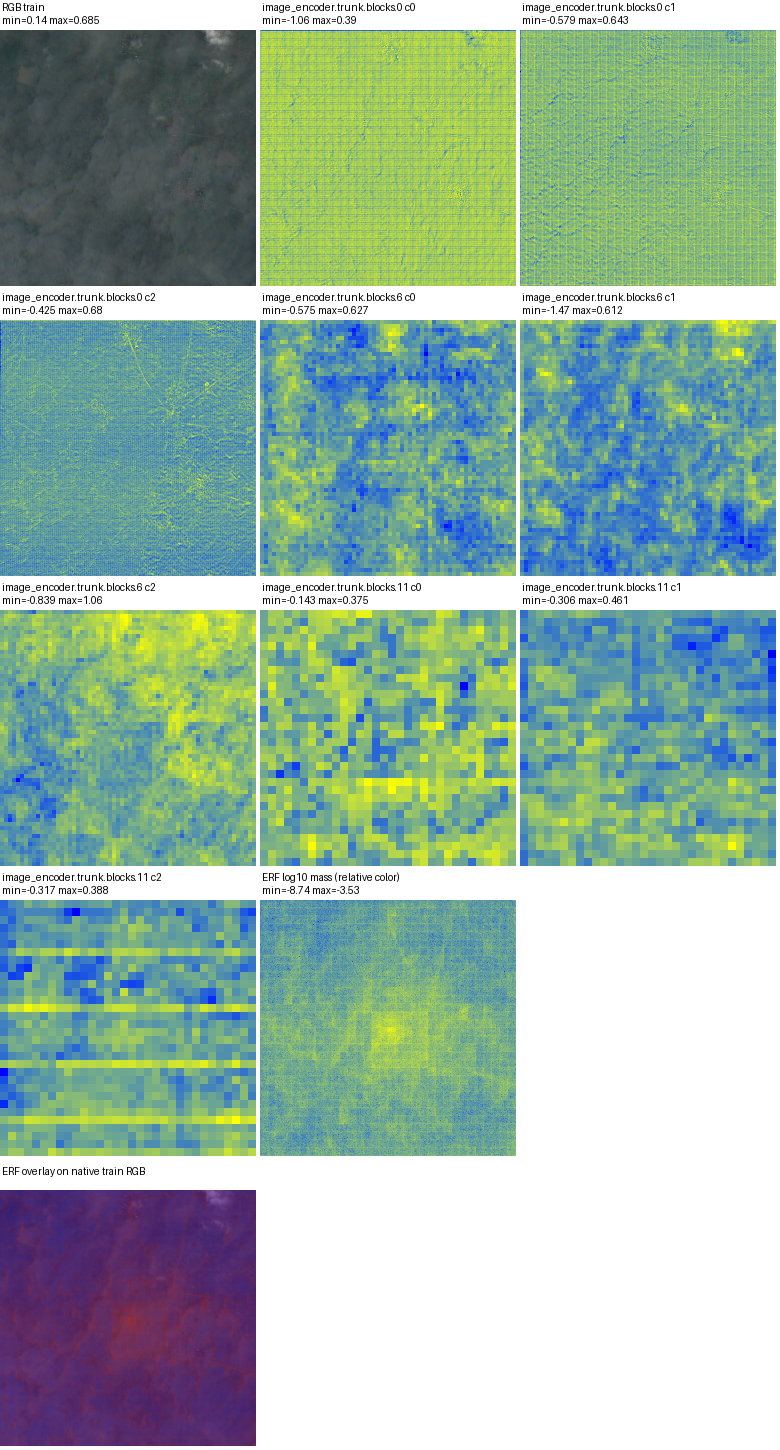

Evidencia completa: /content/drive/MyDrive/auto-prompt-sam2/stage4/evidence/20261030T011345Z_8315d17272_bc78f77e.zip


In [8]:
from IPython.display import display, Image, HTML
import csv, html
RUNS4 = sorted(p for p in (Path(PERSIST_ROOT) / 'stage4/evidence').iterdir() if p.is_dir() and (p / 'validation.json').is_file())
assert RUNS4, 'No hay run completo de la etapa 4; revisa e2/notebook_logs/stage4_sam_prepare.log'
RUN4 = RUNS4[-1]
R4 = json.loads((RUN4 / 'validation.json').read_text())
print('run_id:', R4['run_id'], '| modelos:', R4['identity'].get('models_run'))
print(json.dumps(R4['interpretation']['observed'], indent=1)[:3000])
for table in sorted(RUN4.glob('sam_*_parameters.csv'))[:1] + sorted(RUN4.glob('sam_*_flops.csv'))[:1] + sorted(RUN4.glob('sam_*_timings.csv'))[:1]:
    rows = list(csv.reader(table.open(encoding='utf-8', newline='')))
    print(table.name)
    display(HTML('<table>' + ''.join('<tr>' + ''.join('<td>' + html.escape(v) + '</td>' for v in row) + '</tr>' for row in rows) + '</table>'))
for figure in sorted(RUN4.glob('sam_*_0_figure.png'))[:1]:
    print(figure.name)
    display(Image(filename=str(figure)))
print('Evidencia completa:', RUN4.with_suffix('.zip'))

### (Opcional) Incluir DINOv3
No es necesario para E2 y no bloquea nada. Requiere acceso aprobado a DINOv3 en Hugging Face y el secreto `HF_TOKEN`.

In [9]:
RUN_DINO = False   # True = repetir el teardown incluyendo DINOv3 (gated; requiere HF_TOKEN con acceso aprobado). NO es necesario para E2.
if RUN_DINO:
    command([str(PYTHON), str(REPO / 'scripts/run_stage4.py'), 'prepare', '--models', 'sam,dino', '--root', PERSIST_ROOT], 'stage4_sam_dino_prepare.log')
else:
    print('DINOv3 omitido (opcional).')

DINOv3 omitido (opcional).


## Siguiente
Abre `E2_02_intervencion_decoder.ipynb` (misma carpeta `notebooks/` de la rama `_E.V_`). Guarda **este cuaderno ejecutado** (Archivo → Descargar → .ipynb) y no cambies de commit entre notebooks (queda fijado en `e2/code_commit.txt`). Nada de esto marca E2 como acreditada.